# C3 Respiratory demand: evidence before action
**Group 09 | Ariel Cusacovich and Ana Peris Diaz-Varela | 24 November 2026**

## 1. Question and reading map
**Question:** How did recorded respiratory emergency demand among children under 15 change across 2023–2024, and do simple daily prediction methods support using these records for advance planning?

This study considers the needs of a Metropolitan Region hospital-network planning team. Quarterly comparisons refine the demand story, but the prediction results do not support moving to an operational forecasting pilot. The statistical MA(1) has mixed historical errors and leaves temporal patterns in its residuals; OLS does not beat the reference. Publication timing and genuinely new evaluation data are still needed. These records cannot determine staffing levels or establish a causal explanation for demand changes.

Read sections 2–4 for sources, preparation and EDA; 5–6 for the model and evaluation; 7 for the visual system; and 8 for development, feedback and contributions. Every result needed for assessment is saved here. **No installation, download or execution is required to review this notebook.** No datasets are attached. Optional execution reads fingerprint-verified historical inputs in memory; it needs Python, pandas, NumPy, matplotlib, IPython, statsmodels, SciPy and network access, or an existing W2 folder specified by `C3_W2_DIR`.

The W1 archive was labelled Group 10; the later W2 record corrects this to Group 09. We retain the respiratory route selected in C1, not W1's alternative mental-health route. The separate Group 10 C1 archive is a historical duplicate, not another team's evidence added to this study.

## 2. Identified inputs and preparation
DEIS/MINSAL annual emergency attendance snapshots for 2023 and 2024 are the original sources. The W2 extraction scanned 8,899,080 and 8,973,229 rows respectively and selected provider region 13, establishment type Hospital and causes 1 (all emergencies) and 2 (respiratory). The selected records retain the original fields: 18,974 rows in 2023 and 19,002 in 2024. We rebuild the analytical table from these **uncleaned selected cause records**, rather than trusting saved model results. This run verifies the selected extracts; the national scan counts are the saved W2 extraction record, not a claim that C3 rescanned the national ZIPs.

Original sources: [2023](https://repositoriodeis.minsal.cl/SistemaAtencionesUrgencia/AtencionesUrgencia2023.zip), [2024](https://repositoriodeis.minsal.cl/SistemaAtencionesUrgencia/AtencionesUrgencia2024.zip). Historical inputs and extraction code: [W2 exact version](https://github.com/arielcusacovich/GROUP_09_BI/tree/ba82d9258886fab0857552ea2df7b2cd70bf6e87). The source register records retrieval/verification on 25 September 2026. Retrieval date and event date do not establish publication or revision time; those fields are unavailable.

| Field | Meaning and preparation |
|---|---|
| `IdEstablecimiento`, `fecha`, `IdCausa` | Source unit: hospital–date–cause aggregate. Trim ID whitespace; parse day/month/year. |
| `Menores_1`, `De_1_a_4`, `De_5_a_14` | Counts of visits in three age bands, summed within each cause to obtain under-15 visits. |
| `respiratory`, `all_cause` | Cause 2 and cause 1 reshaped into one hospital-day. Respiratory is a subset: never add the two causes. |
| `share_pct` | 100 × respiratory / all-cause for matching hospitals and dates. Undefined when denominator is zero. |
| `lag7` | Same hospital's count exactly seven calendar days earlier; used by the reference and OLS under a stated availability assumption. |
| `MA(1)` | Statistical model with a fitted hospital mean and one lagged innovation; estimated on 2023 only. |

Counts are encounters, not unique children. Provider region is not residence. Missing reports are not zero visits. The 22-hospital panel requires complete coverage in both years and is used only for descriptive sensitivity; modeling uses all 26 hospitals known in 2023 to avoid selecting hospitals using future completeness.

In [1]:
from pathlib import Path
from io import BytesIO
from urllib.request import urlopen
import os, hashlib, platform, warnings
import statsmodels, scipy
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import kpss
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tools.sm_exceptions import InterpolationWarning
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
COMMIT = 'ba82d9258886fab0857552ea2df7b2cd70bf6e87'
BASE = f'https://raw.githubusercontent.com/arielcusacovich/GROUP_09_BI/{COMMIT}/'
HASHES = {'data/inputs/respiratory_RM_2023_raw.csv': 'f139e197abe318258d8c31cbc434fd079b11c70cca6ee66ca27af54b885db96b', 'data/inputs/respiratory_RM_2024_raw.csv': 'af12a74c65515e73a7577bd8f0a018604cc6c7bdc412f5c760484ddc46f0985d'}
LOCAL = os.environ.get('C3_W2_DIR')
def read_input(name):
    b=(Path(LOCAL)/name).read_bytes() if LOCAL else urlopen(BASE+name,timeout=60).read()
    assert hashlib.sha256(b.replace(b'\r\n',b'\n')).hexdigest()==HASHES[name], 'Source fingerprint mismatch'
    return pd.read_csv(BytesIO(b),dtype={'IdEstablecimiento':str})
raw=pd.concat([read_input(k) for k in HASHES],ignore_index=True)
pd.set_option('display.max_columns',20)
pd.set_option('display.max_rows',30)
pd.set_option('display.width',130)
pd.set_option('display.max_colwidth',90)
print('Verified W2 commit:',COMMIT)
print('Execution inputs:', 'verified local W2 extracts' if LOCAL else 'verified immutable W2 extracts from GitHub')
print('Python',platform.python_version(),'| pandas',pd.__version__,'| NumPy',np.__version__,'| statsmodels',statsmodels.__version__,'| SciPy',scipy.__version__)
display(pd.DataFrame([{'input':k,'SHA256 (normalized line endings)':v} for k,v in HASHES.items()]))
print('Selected source records:',len(raw),'| No source records printed or exported.')

Verified W2 commit: ba82d9258886fab0857552ea2df7b2cd70bf6e87
Execution inputs: verified local W2 extracts
Python 3.12.14 | pandas 3.0.1 | NumPy 2.5.4 | statsmodels 0.15.0 | SciPy 1.18.1
Selected source records: 37976 | No source records printed or exported.


,input,SHA256 (normalized line endings)
0,data/inputs/respiratory_RM_2023_raw.csv,f139e197abe318258d8c31cbc434fd079b11c70cca6ee66ca27af54b885db96b
1,data/inputs/respiratory_RM_2024_raw.csv,af12a74c65515e73a7577bd8f0a018604cc6c7bdc412f5c760484ddc46f0985d


In [2]:
prepared=raw.copy()
prepared['id']=prepared.IdEstablecimiento.str.strip()
prepared['date']=pd.to_datetime(prepared.fecha,format='%d/%m/%Y',errors='raise')
ages=['Menores_1','De_1_a_4','De_5_a_14','De_15_a_64','De_65_y_mas']
for c in ['Total']+ages:prepared[c]=pd.to_numeric(prepared[c],errors='raise')
prepared['under_15']=prepared[ages[:3]].sum(axis=1,min_count=3)
audit=pd.DataFrame([
 ['Missing source cells',int(raw.isna().sum().sum()),'Stop if nonzero'],
 ['Duplicate hospital-date-cause keys',int(prepared.duplicated(['id','date','IdCausa']).sum()),'Stop if nonzero'],
 ['Invalid negative counts',int((prepared[['Total']+ages]<0).sum().sum()),'Stop if nonzero'],
 ['Age-total mismatches',int(prepared.Total.ne(prepared[ages].sum(axis=1)).sum()),'Stop if nonzero'],
 ['ID whitespace corrected',int(raw.IdEstablecimiento.ne(prepared.id).sum()),'Trim derived ID; preserve original'],
 ['Zero under-15 cause counts',int(prepared.under_15.eq(0).sum()),'Retain recorded zeros'],
 ['IDs with changing display names',int(prepared.groupby('id').NEstablecimiento.nunique().gt(1).sum()),'Use stable ID']
],columns=['quality issue','records or IDs','treatment'])
assert audit.iloc[:4,1].eq(0).all()
assert prepared[['Total']+ages].mod(1).eq(0).all().all()
assert prepared.CodigoRegion.eq(13).all() and prepared.GLOSATIPOESTABLECIMIENTO.eq('Hospital').all()
assert set(prepared.IdCausa)=={1,2}
assert prepared.date.between('2023-01-01','2024-12-31').all()
df=prepared.pivot(index=['id','date'],columns='IdCausa',values='under_15').rename(columns={1:'all_cause',2:'respiratory'}).reset_index()
assert not df[['all_cause','respiratory']].isna().any().any()
assert df.respiratory.le(df.all_cause).all()
assert len(raw)==37976 and len(df)==18988 and df.id.nunique()==26
assert prepared.groupby('IdCausa')[ages].sum().equals(raw.groupby('IdCausa')[ages].sum())
df['year']=df.date.dt.year;df['quarter']=df.date.dt.quarter;df['half']=np.where(df.date.dt.month<=6,'H1','H2')
df['share_pct']=100*df.respiratory/df.all_cause.replace(0,np.nan)
assert set(df.loc[df.year==2024,'id'])<=set(df.loc[df.year==2023,'id'])
panel_ids=df.groupby('id').size().loc[lambda s:s==731].index
df['complete_panel']=df.id.isin(panel_ids);assert len(panel_ids)==22
coverage=pd.DataFrame([{'year':y,'observed hospital-days':len(g),'expected (26 hospitals)':26*(366 if y==2024 else 365),'absent reports':26*(366 if y==2024 else 365)-len(g),'zero respiratory days':int(g.respiratory.eq(0).sum()),'undefined shares':int(g.share_pct.isna().sum())} for y,g in df.groupby('year')])
display(audit);display(coverage)
display(pd.DataFrame({'stage':['Selected cause rows','Prepared cause rows','Paired hospital-days','Fixed-panel hospital-days'],'records':[len(raw),len(prepared),len(df),int(df.complete_panel.sum())]}))
print('No source rows or visits deleted. Two cause rows become one hospital-day; 18 absent reports remain absent.')

No source rows or visits deleted. Two cause rows become one hospital-day; 18 absent reports remain absent.


,quality issue,records or IDs,treatment
0,Missing source cells,0,Stop if nonzero
1,Duplicate hospital-date-cause keys,0,Stop if nonzero
2,Invalid negative counts,0,Stop if nonzero
3,Age-total mismatches,0,Stop if nonzero
4,ID whitespace corrected,2902,Trim derived ID; preserve original
5,Zero under-15 cause counts,12385,Retain recorded zeros
6,IDs with changing display names,2,Use stable ID


,year,observed hospital-days,expected (26 hospitals),absent reports,zero respiratory days,undefined shares
0,2023,9487,9490,3,3261,2902
1,2024,9501,9516,15,3284,2938


,stage,records
0,Selected cause rows,37976
1,Prepared cause rows,37976
2,Paired hospital-days,18988
3,Fixed-panel hospital-days,16082


## 3. EDA and the corrections that matter
We inspect the target distribution by year, reporting zeros separately. A right-skewed count distribution and many zeros make percentage error unsuitable; MAE remains defined at zero. We retain genuine high-count days instead of deleting them as outliers. Pooling error across hospitals gives every observed hospital-day equal weight and can hide poor performance at high-volume providers.

The original KPI is a ratio of matched totals, not an average of hospital percentages. The next table separates the historical 22-hospital scope from the 26-hospital scope used in the model. The 19.17% initially reported in C1 was a transcription error: the historical 2023 share is 29.17%, and the change is about −2.52 percentage points. Peñaflor's equal annual respiratory totals are checked against age composition and daily values rather than automatically treated as duplicate data.

In [3]:
display(df.groupby('year').respiratory.describe(percentiles=[.25,.5,.75,.95]).round(2))
annual=[]
for scope,mask in [('Fixed 22',df.complete_panel),('Observed 26',pd.Series(True,index=df.index))]:
    for y,g in df[mask].groupby('year'):
        annual.append({'scope':scope,'year':y,'respiratory':int(g.respiratory.sum()),'all_cause':int(g.all_cause.sum()),'share_pct':100*g.respiratory.sum()/g.all_cause.sum()})
annual=pd.DataFrame(annual);display(annual.round(3))
pen=prepared[prepared.NEstablecimiento.str.contains('Peñaflor',case=False,na=False)&prepared.IdCausa.eq(2)].copy()
assert pen.id.nunique()==1
pen['year']=pen.date.dt.year
display(pen.groupby('year')[ages[:3]+['under_15']].sum())
pen['month_day']=pen.date.dt.strftime('%m-%d')
matched=pen.pivot(index='month_day',columns='year',values='under_15').dropna()
print('Peñaflor: unequal values on',int(matched[2023].ne(matched[2024]).sum()),'of',len(matched),'matched calendar days.')
print('Equal annual totals do not imply identical daily records; no deletion is justified by this coincidence alone.')

Peñaflor: unequal values on 352 of 365 matched calendar days.
Equal annual totals do not imply identical daily records; no deletion is justified by this coincidence alone.


,count,mean,std,min,25%,50%,75%,95%,max
year,,,,,,,,,
2023,9487.0,19.44,24.04,0.0,0.0,11.0,31.0,67.0,162.0
2024,9501.0,17.24,21.15,0.0,0.0,9.0,28.0,61.0,136.0


,scope,year,respiratory,all_cause,share_pct
0,Fixed 22,2023,178704,612611,29.171
1,Fixed 22,2024,159173,597321,26.648
2,Observed 26,2023,184414,625745,29.471
3,Observed 26,2024,163832,609187,26.894


,Menores_1,De_1_a_4,De_5_a_14,under_15
year,,,,
2023,1408,3353,3685,8446
2024,1094,3026,4326,8446


## 4. Do semester patterns repeat within quarters?
We compare 2024 with the same quarter of 2023, using the same 22 complete hospitals in every quarter. The percentage denominator is the corresponding 2023 respiratory count. We also show all-cause denominators and observed hospital-days, and check visits per hospital-day to account for the extra day in Q1 2024. All 26 hospitals provide a second sensitivity comparison, not a probability-weighted estimate of regional incidence.

In [4]:
periods=[]
for scope,mask in [('Fixed 22',df.complete_panel),('Observed 26',pd.Series(True,index=df.index))]:
    for unit in ['half','quarter']:
        for period,g in df[mask].groupby(unit):
            a=g[g.year==2023];b=g[g.year==2024]
            periods.append({'scope':scope,'period':str(period) if unit=='half' else 'Q'+str(period),'visits_2023':int(a.respiratory.sum()),'visits_2024':int(b.respiratory.sum()),'days_2023':len(a),'days_2024':len(b),'all_cause_2023':int(a.all_cause.sum()),'all_cause_2024':int(b.all_cause.sum()),'change_pct':100*(b.respiratory.sum()/a.respiratory.sum()-1),'intensity_change_pct':100*((b.respiratory.sum()/len(b))/(a.respiratory.sum()/len(a))-1)})
periods=pd.DataFrame(periods)
display(periods[periods.scope.eq('Fixed 22')].round(3))
display(periods[periods.scope.eq('Observed 26')][['period','change_pct','intensity_change_pct']].round(3))

,scope,period,visits_2023,visits_2024,days_2023,days_2024,all_cause_2023,all_cause_2024,change_pct,intensity_change_pct
0,Fixed 22,H1,99294,72903,3982,4004,314338,282034,-26.579,-26.982
1,Fixed 22,H2,79410,86270,4048,4048,298273,315287,8.639,8.639
2,Fixed 22,Q1,32380,22985,1980,2002,136942,123740,-29.015,-29.795
3,Fixed 22,Q2,66914,49918,2002,2002,177396,158294,-25.400,-25.400
4,Fixed 22,Q3,36740,46357,2024,2024,131620,154230,26.176,26.176
5,Fixed 22,Q4,42670,39913,2024,2024,166653,161057,-6.461,-6.461


,period,change_pct,intensity_change_pct
6,H1,-26.731,-27.041
7,H2,8.309,8.445
8,Q1,-28.767,-29.550
9,Q2,-25.748,-25.560
10,Q3,25.861,26.019
11,Q4,-6.710,-6.593


**Finding:** in the fixed panel, H1 falls **26.58%** and H2 rises **8.64%**. Q1 and Q2 fall **29.01%** and **25.40%**; Q3 rises **26.18%**, but Q4 falls **6.46%**. Therefore the H1 direction repeats across both quarters, whereas the H2 increase does not. Q1 intensity falls 29.79%, so the leap day does not reverse the result. These are year-on-year comparisons over only two years; they do not establish a recurring seasonal law or its cause. Semester totals are weighted combinations of quarterly totals, not simple averages of quarterly percentage changes.

## 5. Model, reference and valid evaluation
We retain the C2 split: train = 2023; validation = Jan–Jun 2024; historical test = Jul–Dec 2024. We predict the next daily count at hospitals already known in 2023. Repeated hospitals are intentional. Randomly splitting rows would mix earlier and later dates.

**Reference and retained comparison.** The reference repeats the same hospital's count exactly seven calendar days earlier: a single observed count from the same weekday last week. The C2 OLS fits an intercept and lag7 coefficient on 2023 only. If lag7 is absent, both use the 2023 lag7 median (11). Missing reports are not treated as zero. We retain OLS to show whether the earlier fitted adjustment improved on its reference.

**Statistical moving-average model.** We add a separate MA(1) for each hospital with nonconstant training counts:

$$y_{h,t}=\mu_h+\varepsilon_{h,t}+\theta_h\varepsilon_{h,t-1}.$$

Here, $\varepsilon$ is a zero-mean innovation and $\theta$ weights the previous innovation; it does not weight yesterday's raw count. We estimate the mean, coefficient and innovation variance by Gaussian state-space likelihood using `ARIMA(order=(0,0,1), trend='c')` on 2023 only, with invertibility enforced. Order q=1 is the smallest nontrivial MA model, chosen for a transparent comparison; no order search is performed and we do not claim it is optimal. The seven constant-zero training series use a declared zero prediction instead of an unidentified variance/coefficient fit. All 26 hospitals remain in evaluation. The 19 fitted models have separate hospital parameters, whereas C2 OLS is pooled; this compares complete prediction procedures, not the isolated effect of one coefficient.

Each hospital is reindexed to actual calendar days. Absent reports remain NaN and are handled by the state-space filter. Parameters stay fixed when 2024 observations are appended with `refit=False`. `get_prediction(..., dynamic=False, information_set='predicted')` returns a one-step prediction using information through t−1, never the target at t. We check this against direct forecasts made from truncated histories. Counts cannot be negative, so MA(1) predictions are clipped at zero, as for OLS; raw-error sensitivity and the number clipped are saved. The Gaussian likelihood is a working approximation to counts, not a claim of normally distributed visits or calibrated prediction intervals.

**Assumptions and availability.** A pure MA(1) has a stable mean and short innovation memory. We inspect training stationarity and residual dependence below. Poor diagnostics prevent presenting it as an adequate operational model. At a hypothetical 00:00 decision, yesterday's count may not be published. MA(1) assumes sufficiently timely past observations, including the previous day; calendar ordering does not prove publication availability. Sequential daily evaluation uses earlier outcomes for later predictions but never refits parameters on 2024. It is not a six-month-ahead forecast issued on 1 July.

**Evaluation status.** W1/C1 explored both years, C2 reported test results, and the MA(1) extension followed feedback. We report the original validation and test periods separately, without pretending either is newly untouched evidence. Specifications remain fixed for this comparison. A genuinely new period is needed for confirmation, including if a method has the lowest historical error. An unfavorable result is retained.

Method references: [Statistical MA(q) definition](https://otexts.com/fpp3/arima.html#moving-average-models); [statsmodels ARIMA](https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html) and [sequential forecasting](https://www.statsmodels.org/stable/examples/notebooks/generated/statespace_forecasting.html).

In [5]:
model_data=df.sort_values(['date','id']).copy()
lag=df[['id','date','respiratory']].rename(columns={'respiratory':'lag7'})
lag['date']=lag.date+pd.Timedelta(days=7)
model_data=model_data.merge(lag,on=['id','date'],how='left',validate='one_to_one')
model_data['split']=np.where(model_data.date<'2024-01-01','train',np.where(model_data.date<'2024-07-01','validation','test'))
parts={s:model_data[model_data.split.eq(s)].copy() for s in ['train','validation','test']}
assert [len(parts[s]) for s in parts]==[9487,4726,4775]
median=float(parts['train'].lag7.median())
x=parts['train'].lag7.fillna(median).to_numpy()
beta=np.linalg.lstsq(np.column_stack([np.ones(len(x)),x]),parts['train'].respiratory.to_numpy(),rcond=None)[0]
for g in parts.values():
    g['Reference']=g.lag7.fillna(median)
    g['OLS']=np.maximum(0,beta[0]+beta[1]*g.Reference)
    g['observed_lag7']=g.lag7.notna()
    assert np.isfinite(g[['Reference','OLS']]).all().all()
display(pd.DataFrame([{'split':s,'rows':len(g),'hospitals':g.id.nunique(),'missing_lag7':int(g.lag7.isna().sum())} for s,g in parts.items()]))
print(f'Training-only median: {median:.0f}; OLS prediction = max(0, {beta[0]:.6f} + {beta[1]:.6f} × lag7).')

Training-only median: 11; OLS prediction = max(0, 1.578497 + 0.919658 × lag7).


,split,rows,hospitals,missing_lag7
0,train,9487,26,184
1,validation,4726,26,5
2,test,4775,26,9


In [6]:
calendar=pd.date_range('2023-01-01','2024-12-31',freq='D')
ma_predictions=[]; ma_parameters=[]; diagnostic_rows=[]; leakage_checks=[]
for hospital,g in df.groupby('id',sort=True):
    y=g.set_index('date').respiratory.reindex(calendar).astype(float)
    train_y=y.loc[:'2023-12-31']; future_y=y.loc['2024-01-01':]
    record={'hospital':hospital,'train_days':int(train_y.notna().sum())}
    if train_y.dropna().nunique()==1:
        value=float(train_y.dropna().iloc[0])
        predicted=pd.Series(value,index=future_y.index)
        record.update(status='constant rule',mean=value,theta=0.0,variance=0.0,converged=None,fit_warnings=0)
    else:
        with warnings.catch_warnings(record=True) as fit_warnings:
            warnings.simplefilter('always')
            fitted=ARIMA(train_y,order=(0,0,1),trend='c',enforce_invertibility=True).fit(method_kwargs={'maxiter':500})
        assert fitted.mle_retvals['converged'], f'Fit did not converge: {hospital}'
        assert np.isfinite(fitted.params).all() and abs(fitted.params['ma.L1'])<1
        record.update(status='fitted MA(1)',mean=fitted.params['const'],theta=fitted.params['ma.L1'],variance=fitted.params['sigma2'],converged=True,fit_warnings=len(fit_warnings))
        for w in fit_warnings: print('Fit warning:',hospital,str(w.message))
        updated=fitted.append(future_y,refit=False)
        np.testing.assert_allclose(updated.params,fitted.params,rtol=0,atol=0)
        predicted=updated.get_prediction(start='2024-01-01',end='2024-12-31',dynamic=False,information_set='predicted').predicted_mean
        for decision_date in ['2024-01-01','2024-07-01']:
            past=future_y.loc[:pd.Timestamp(decision_date)-pd.Timedelta(days=1)]
            prior=fitted.append(past,refit=False) if len(past) else fitted
            difference=abs(float(prior.forecast(1).iloc[0])-float(predicted.loc[decision_date]))
            assert difference<1e-9
            leakage_checks.append(difference)
        # Diagnostics require uninterrupted training days: do not compress gaps.
        if train_y.notna().all():
            with warnings.catch_warnings(record=True) as kpss_warnings:
                warnings.simplefilter('always')
                stat,p_value,lags,_=kpss(train_y,regression='c',nlags='auto',result_object=False)
            assert all(issubclass(w.category,InterpolationWarning) for w in kpss_warnings), [(w.category.__name__,str(w.message)) for w in kpss_warnings]
            label='>0.10' if p_value==.1 else ('<0.01' if p_value==.01 else f'{p_value:.4f}')
            errors=np.asarray(fitted.filter_results.standardized_forecasts_error[0])[1:]
            lb=acorr_ljungbox(errors,lags=[14],model_df=1,return_df=True)
            diagnostic_rows.append({'hospital':hospital,'KPSS statistic':stat,'KPSS p (bounded)':label,'KPSS lags':int(lags),'KPSS nominal flag':p_value<.05,'LB14 p':float(lb.lb_pvalue.iloc[0])})
    ma_parameters.append(record)
    ma_predictions.append(predicted.rename('MA1_raw').rename_axis('date').reset_index().assign(id=hospital))
ma_parameters=pd.DataFrame(ma_parameters)
ma_predictions=pd.concat(ma_predictions,ignore_index=True)
diagnostics=pd.DataFrame(diagnostic_rows)
diagnostics['LB14 Bonferroni flag']=diagnostics['LB14 p']<.05/len(diagnostics)
for period in ['validation','test']:
    parts[period]=parts[period].merge(ma_predictions,on=['id','date'],how='left',validate='one_to_one')
    parts[period]['MA(1)']=parts[period].MA1_raw.clip(lower=0)
    assert parts[period]['MA(1)'].notna().all()
display(ma_parameters.round(5))
print('Fitted MA(1):',ma_parameters.status.eq('fitted MA(1)').sum(),'| Constant rules:',ma_parameters.status.eq('constant rule').sum())
print('Fit warnings:',ma_parameters.fit_warnings.sum(),'| Direct past-only checks:',len(leakage_checks),'| Maximum prediction difference:',max(leakage_checks))

Fitted MA(1): 19 | Constant rules: 7
Fit warnings: 0 | Direct past-only checks: 38 | Maximum prediction difference: 0.0


,hospital,train_days,status,mean,theta,variance,converged,fit_warnings
0,09-100,365,constant rule,0.00000,0.00000,0.00000,None,0
1,09-101,365,fitted MA(1),51.90844,0.56821,218.74651,True,0
2,09-102,363,constant rule,0.00000,0.00000,0.00000,None,0
3,09-104,365,fitted MA(1),8.17230,0.43258,23.87951,True,0
4,10-100,365,fitted MA(1),0.01096,-0.01143,0.01084,True,0
5,10-110,365,constant rule,0.00000,0.00000,0.00000,None,0
6,10-120,365,fitted MA(1),41.20169,0.45713,137.83138,True,0
7,10-130,365,fitted MA(1),9.30217,0.42239,27.14791,True,0
8,10-140,365,fitted MA(1),23.13141,0.51964,124.12438,True,0
9,10-150,365,fitted MA(1),15.64241,0.49181,66.53748,True,0


### Training diagnostics and what they mean
KPSS checks the null of stationarity around a constant, using automatic lag selection. Values outside its lookup table are reported as bounds. A non-rejection is not proof of a stable process. Ljung–Box checks residual autocorrelation through 14 days, allowing one fitted MA coefficient (`model_df=1`). We remove the first standardized prediction error to reduce initialization effects. To preserve calendar spacing, both diagnostics cover only the **18 fitted hospitals with all 365 training days**; the one fitted hospital with a gap and seven constant rules are excluded from tests but remain in prediction evaluation.

Three of 18 KPSS tests flag nonstationarity at the individual 5% level; these are exploratory flags without a multiple-test claim. Residual autocorrelation is much clearer: **17 of 18** Ljung–Box p-values are below the conservative threshold **0.05/18**. Thus MA(1) leaves substantial temporal structure unexplained. Convergence and invertibility do not establish model adequacy. We retain the requested model comparison as negative evidence, rather than recommending this specification for deployment or adding orders until a favorable result appears.

Diagnostic references: [KPSS](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.kpss.html) and [Ljung–Box](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.acorr_ljungbox.html).

In [7]:
diag_view=diagnostics.rename(columns={'KPSS p (bounded)':'KPSS p','KPSS nominal flag':'KPSS flag','LB14 Bonferroni flag':'LB corrected flag'}).copy()
diag_view['KPSS statistic']=diag_view['KPSS statistic'].round(3)
diag_view['LB14 p']=diag_view['LB14 p'].map(lambda v:f'{v:.2e}')
display(diag_view)
print('KPSS nominal flags:',int(diagnostics['KPSS nominal flag'].sum()),'of',len(diagnostics))
print('Residual-dependence flags at 0.05 /',len(diagnostics),':',int(diagnostics['LB14 Bonferroni flag'].sum()))
METHODS=['Reference','OLS','MA(1)']
metrics=[]; clipping=[]
for period in ['validation','test']:
    g=parts[period]
    for method in METHODS:
        metrics.append({'period':period,'method':method,'rows':len(g),'MAE':float(abs(g.respiratory-g[method]).mean())})
    clipping.append({'period':period,'negative raw predictions':int(g.MA1_raw.lt(0).sum()),'MA1 raw MAE':float(abs(g.respiratory-g.MA1_raw).mean()),'MA1 clipped MAE':float(abs(g.respiratory-g['MA(1)']).mean())})
metrics=pd.DataFrame(metrics)
display(metrics.round(4))
display(pd.DataFrame(clipping).round(8))
chosen=metrics[metrics.period.eq('validation')].sort_values('MAE').iloc[0]['method']
print('Lowest historical validation MAE:',chosen,'| The reference remains the comparator; no operational model is approved.')

KPSS nominal flags: 3 of 18
Residual-dependence flags at 0.05 / 18 : 17
Lowest historical validation MAE: Reference | The reference remains the comparator; no operational model is approved.


,hospital,KPSS statistic,KPSS p,KPSS lags,KPSS flag,LB14 p,LB corrected flag
0,09-101,0.336,>0.10,11,False,1.60e-222,True
1,09-104,0.312,>0.10,10,False,3.34e-82,True
2,10-100,0.132,>0.10,2,False,4.53e-02,False
3,10-120,0.401,0.0767,10,False,5.26e-112,True
4,10-130,0.350,0.0985,10,False,4.81e-106,True
5,10-140,0.339,>0.10,11,False,4.91e-200,True
6,10-150,0.291,>0.10,11,False,1.96e-183,True
7,10-160,0.267,>0.10,11,False,7.44e-157,True
8,11-100,0.371,0.0896,11,False,7.45e-187,True
9,11-101,0.318,>0.10,10,False,4.58e-184,True


,period,method,rows,MAE
0,validation,Reference,4726,4.9435
1,validation,OLS,4726,5.3849
2,validation,MA(1),4726,6.3258
3,test,Reference,4775,4.9964
4,test,OLS,4775,5.3972
5,test,MA(1),4775,4.7798


,period,negative raw predictions,MA1 raw MAE,MA1 clipped MAE
0,validation,1,6.325760,6.325760
1,test,5,4.779825,4.779825


In [8]:
sensitivity=[]
for period in ['validation','test']:
    for method in METHODS:
        g=parts[period].loc[lambda x:x.observed_lag7]
        sensitivity.append({'period':period,'method':method,'same observed-lag7 rows':len(g),'MAE':float(abs(g.respiratory-g[method]).mean())})
display(pd.DataFrame(sensitivity).round(4))
test=parts['test'].copy()
hospital_errors=pd.DataFrame({m:test.assign(error=abs(test.respiratory-test[m])).groupby('id').error.mean() for m in METHODS})
display(hospital_errors.describe(percentiles=[.25,.5,.75]).round(3))
print('MA(1) lower test MAE than reference at',int(hospital_errors['MA(1)'].lt(hospital_errors.Reference).sum()),'of',len(hospital_errors),'hospitals')
top=test.respiratory>=parts['train'].respiratory.quantile(.95)
display(pd.DataFrame([{'method':m,'test high-demand rows':int(top.sum()),'threshold (2023 95th percentile)':parts['train'].respiratory.quantile(.95),'MAE':abs(test.loc[top,'respiratory']-test.loc[top,m]).mean()} for m in METHODS]).round(3))

MA(1) lower test MAE than reference at 12 of 26 hospitals


,period,method,same observed-lag7 rows,MAE
0,validation,Reference,4721,4.9386
1,validation,OLS,4721,5.3797
2,validation,MA(1),4721,6.3324
3,test,Reference,4766,4.9864
4,test,OLS,4766,5.3866
5,test,MA(1),4766,4.7852


,Reference,OLS,MA(1)
count,26.000,26.000,26.000
mean,4.990,5.392,4.773
std,4.430,3.701,4.368
min,0.000,1.576,0.000
25%,0.095,1.582,0.009
50%,4.864,4.772,4.514
75%,9.181,8.913,8.643
max,12.495,12.166,12.654


,method,test high-demand rows,threshold (2023 95th percentile),MAE
0,Reference,161,67.0,13.472
1,OLS,161,67.0,15.031
2,MA(1),161,67.0,15.265


## 6. Interpretation and supported next step
The comparison uses the same **4,726 validation hospital-days** and the same **4,775 test hospital-days** for all three methods. The reference has the lowest validation MAE: **4.9435 visits**, compared with **5.3849** for OLS and **6.3258** for MA(1). In the historical test, MA(1) has MAE **4.7798**, compared with **4.9964** for the reference and **5.3972** for OLS. MA(1) therefore improves the pooled test error slightly but performs worse in validation. This is mixed evidence, not a consistent gain or a statistical-significance claim.

MA(1) has lower test MAE than the reference at **12 of 26 hospitals**. On **161 high-demand test hospital-days**, defined using the 2023 95th percentile of **67 visits**, its MAE is **15.265**, above the reference's **13.472** and OLS's **15.031**. The small pooled test advantage does not hold on these high-demand days. The observed-lag7 sensitivity uses identical rows with a recorded lag7 for all methods, separating the comparison from the reference's imputation rule. The MA(1) comparison includes 19 fitted models and seven constant-zero rules. Clipping affects one validation and five test predictions, with negligible changes in MAE.

The training diagnostics are a second reason for caution: residual dependence remains in 17 of 18 tested complete series after correction. A pure MA(1) does not adequately describe their temporal structure. OLS also remains useful negative evidence: fitting a linear adjustment of last week's value did not improve MAE in either period. A small average error is not a staffing rule, and no intervention effect is identified.

**Recommendation:** keep quarterly demand review, but do not use these fitted models to change staffing or begin an operational forecasting pilot. Obtain publication/revision histories first. If timely inputs are available, examine the remaining temporal structure using training data, retain the lag7 reference, freeze a revised specification and evaluate a genuinely new period. If timely inputs are unavailable, revise the availability rule before any evaluation. Include hospital and high-demand diagnostics, and have planners define acceptable error and service costs before considering a pilot. These are next steps, not analyses already completed in this study.

## 7. Implemented visual system
Recorded data use dark gray; the lag7 reference uses blue; OLS uses orange; statistical MA(1) uses purple. These meanings are stable. Bars have zero baselines, chronological periods and direct value labels; prediction methods also have distinct patterns. Monthly panels share a scale and use different markers and line styles. Counts, percentage changes and MAE have separate axes with explicit units. Percent changes and MAE labels use two decimals; monthly totals use whole visits. Shared plotting settings below generate every final chart.

We retain W3's signed comparisons and direct labels, extend the method chart to MA(1), and retain common-scale monthly panels as supporting evidence. We replace the semester-only headline with quarters because it concealed the Q4 decline. Histograms reveal the zero-heavy distribution; the monthly panels summarize timing rather than proving daily accuracy.

**Design trade-offs:** quarter bars hide hospital variation, but clarify the scope of the semester claim; a next view could split the fixed panel by hospital. MAE bars hide error direction and tails, so we also report hospital and high-demand summaries. Monthly averaging hides daily peaks and separated panels require eye movement; we retain them to avoid overlapping lines and would inspect daily errors for any operational review.

Monthly scope: 26 observed hospitals, Jul–Dec 2024; identical records across methods; absent reports are not zeros.


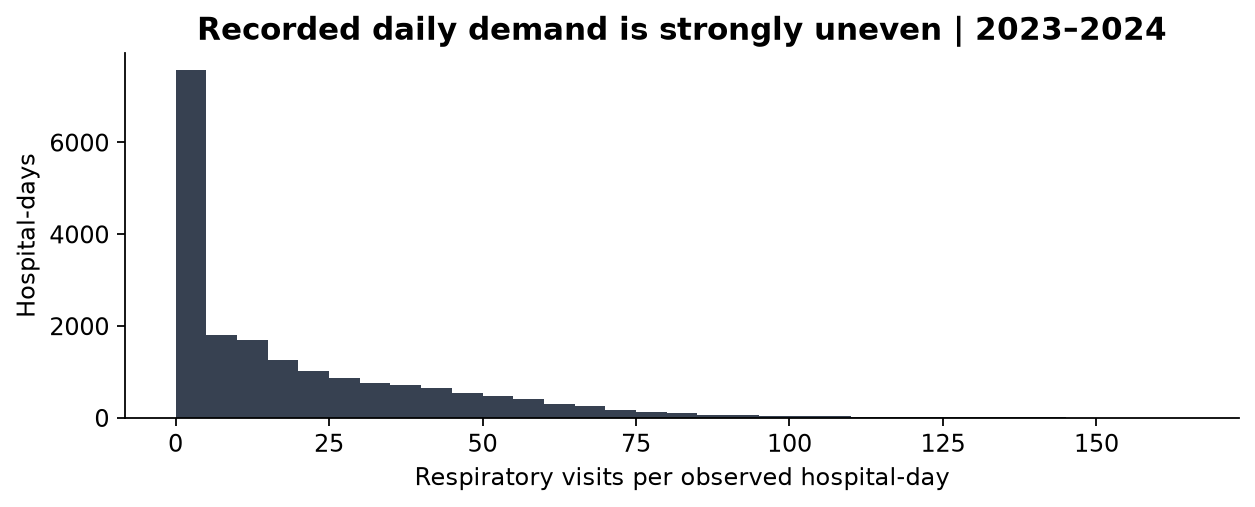

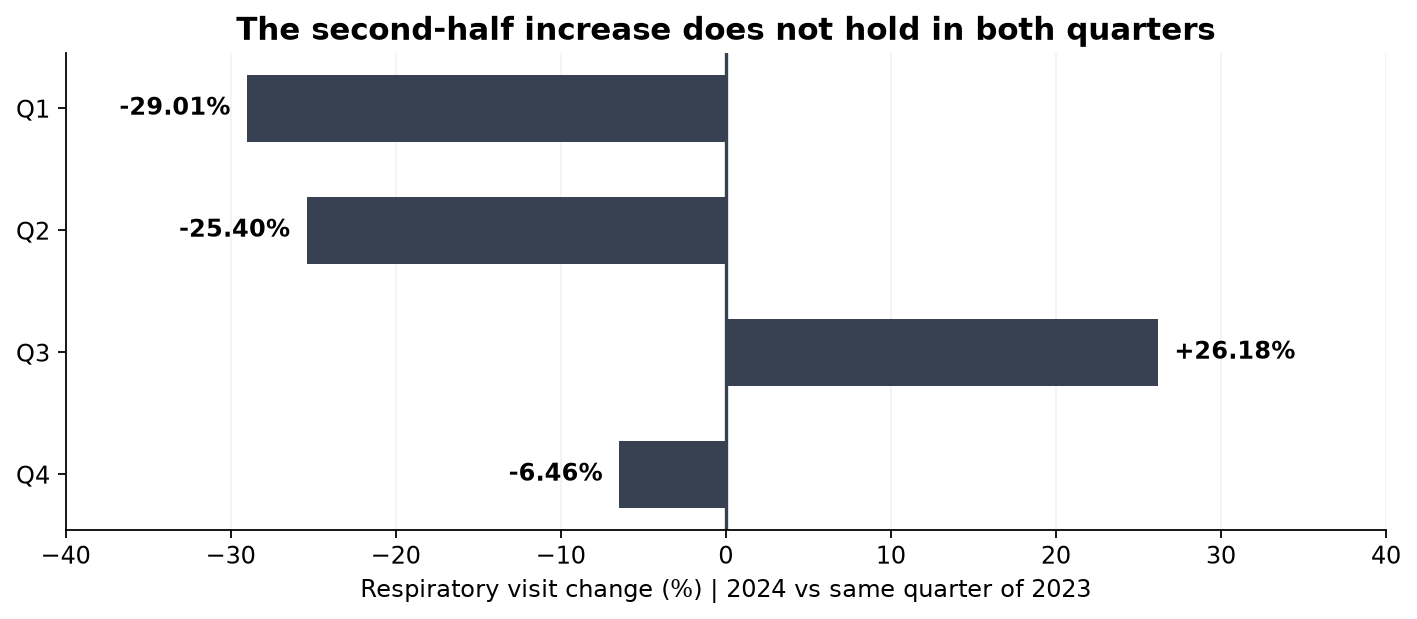

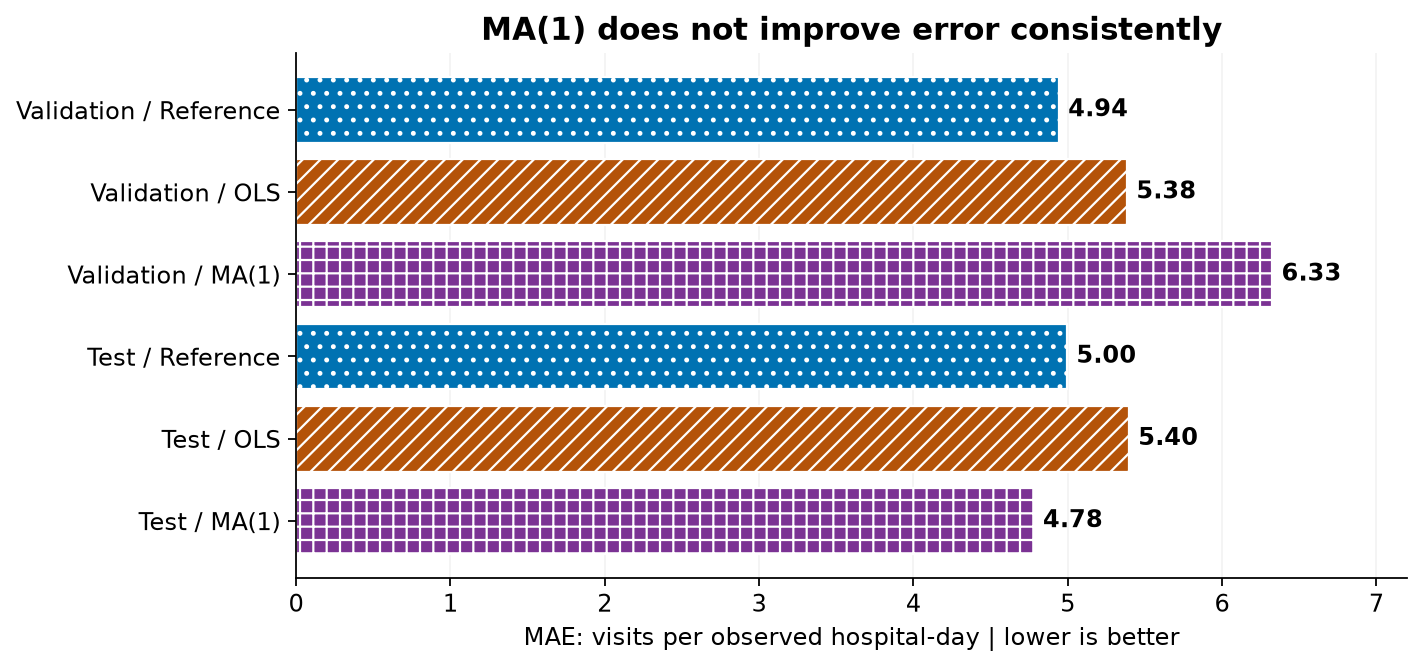

,Observed,Reference,OLS,MA(1)
Jul,457.16,416.26,423.70,486.93
Aug,565.68,580.42,574.83,527.51
Sep,528.37,542.40,539.86,511.84
Oct,491.39,489.23,490.81,500.23
Nov,490.87,489.43,491.15,499.79
Dec,362.42,420.61,427.71,456.48


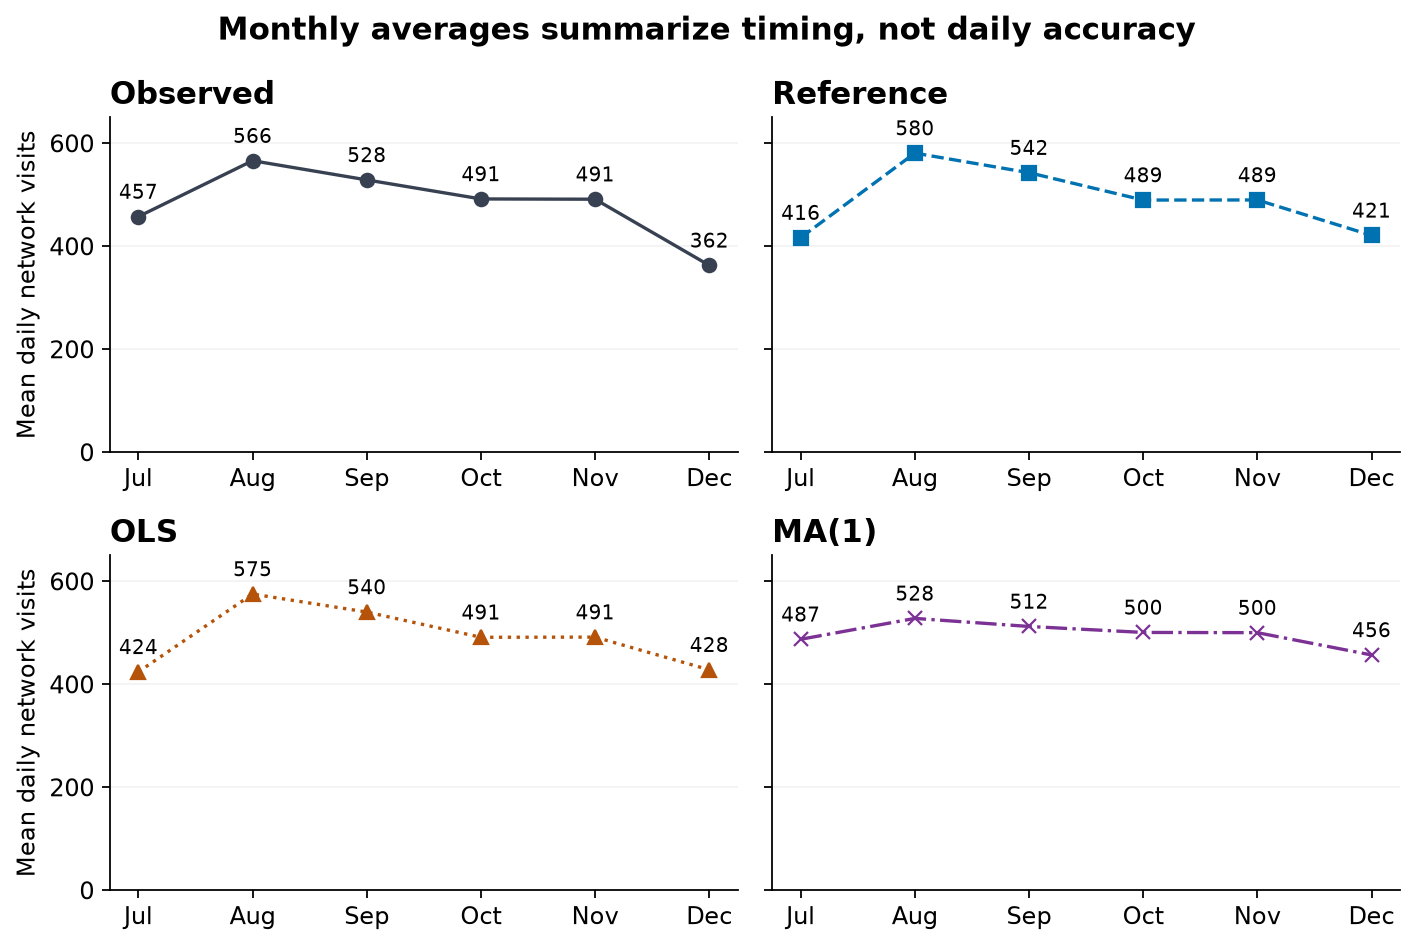

In [9]:
COLORS={'Observed':'#374151','Reference':'#0072B2','OLS':'#B45309','MA(1)':'#7B3294'}
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.titlesize':14,'axes.titleweight':'bold','axes.labelsize':11,'axes.spines.top':False,'axes.spines.right':False,'figure.facecolor':'white'})
FIGURES={}
def show(fig,key):
    fig.tight_layout();b=BytesIO();fig.savefig(b,format='png',dpi=160,bbox_inches='tight')
    FIGURES[key]=b.getvalue();display(Image(data=FIGURES[key]));plt.close(fig)
fig,ax=plt.subplots(figsize=(8,3.3))
ax.hist(df.respiratory,bins=np.arange(0,df.respiratory.max()+6,5),color=COLORS['Observed'])
ax.set(xlabel='Respiratory visits per observed hospital-day',ylabel='Hospital-days',title='Recorded daily demand is strongly uneven | 2023–2024')
show(fig,'distribution')
fig,ax=plt.subplots(figsize=(9,4))
q=periods[periods.scope.eq('Fixed 22')&periods.period.str.startswith('Q')]
ax.barh(q.period,q.change_pct,color=COLORS['Observed'],height=.55);ax.invert_yaxis();ax.set_xlim(-40,40);ax.axvline(0,color='#374151');ax.grid(axis='x',alpha=.15);ax.set_axisbelow(True)
for i,v in enumerate(q.change_pct):ax.text(v+(1 if v>=0 else -1),i,f'{v:+.2f}%',va='center',ha='left' if v>=0 else 'right',weight='bold')
ax.set(xlabel='Respiratory visit change (%) | 2024 vs same quarter of 2023',title='The second-half increase does not hold in both quarters')
show(fig,'quarters')
fig,ax=plt.subplots(figsize=(9,4.3))
labels=[]
for i,row in metrics.iterrows():
    ax.barh(i,row.MAE,color=COLORS[row.method],hatch={'Reference':'..','OLS':'///','MA(1)':'++'}[row.method],edgecolor='white')
    ax.text(row.MAE+.06,i,f'{row.MAE:.2f}',va='center',weight='bold');labels.append(row.period.title()+' / '+row.method)
ax.set_yticks(range(len(metrics)),labels);ax.invert_yaxis();ax.set_xlim(0,7.2);ax.set_axisbelow(True);ax.grid(axis='x',alpha=.15)
ax.set(xlabel='MAE: visits per observed hospital-day | lower is better',title='MA(1) does not improve error consistently')
show(fig,'errors')
daily=test.groupby('date')[['respiratory']+METHODS].sum().rename(columns={'respiratory':'Observed'})
monthly=daily.groupby(daily.index.month).mean();monthly.index=['Jul','Aug','Sep','Oct','Nov','Dec']
display(monthly.round(2))
fig,axes=plt.subplots(2,2,figsize=(9,6),sharex=True,sharey=True)
for ax,col,marker,line in zip(axes.flat,monthly.columns,['o','s','^','x'],['-','--',':','-.']):
    ax.plot(range(6),monthly[col],color=COLORS[col],marker=marker,linestyle=line)
    ax.set_title(col,loc='left');ax.set_ylim(0,650);ax.set_xticks(range(6),monthly.index);ax.grid(axis='y',alpha=.15)
    for j,v in enumerate(monthly[col]):ax.annotate(f'{v:.0f}',(j,v),xytext=(0,8),textcoords='offset points',ha='center',fontsize=9)
for ax in axes.flat:ax.tick_params(labelbottom=True)
for ax in axes[:,0]:ax.set_ylabel('Mean daily network visits')
fig.suptitle('Monthly averages summarize timing, not daily accuracy',fontsize=14,weight='bold')
show(fig,'monthly')
print('Monthly scope: 26 observed hospitals, Jul–Dec 2024; identical records across methods; absent reports are not zeros.')

## 8. Development, feedback and contributions
| Stage or feedback | Decision and supporting evidence | Effect on the final message |
|---|---|---|
| W1: compare respiratory and mental-health routes | Keep respiratory demand under 15, the route selected in C1. | One population and decision question across the study. |
| C1: incorrect 19.17% value; −2.52 pp mismatch | Recompute the fixed-panel ratio of totals: 29.17% in 2023 and 26.65% in 2024 (section 3). | Use the corrected KPI; distinguish percentage points from percent changes. |
| C1: 22 hospitals may select the population | Report fixed 22 and observed 26 separately (sections 2 and 4). | No claim of representativeness; no future-completeness selection for modeling. |
| C1: equal Peñaflor totals | Check age composition and matched daily counts (section 3). | Keep valid observations; equal totals alone do not establish duplication. |
| W2: exact version missing | Pin SHA ba82d9258886fab0857552ea2df7b2cd70bf6e87 and input hashes (section 2). | Results have an identifiable source version. |
| C2: same-panel semesters; coverage, denominators and publication | Keep separate tables and the historical-availability caveat. | No real-time or staffing claim. |
| C2: simple OLS failed to beat reference | Retain the result and frozen training specification (section 5). | Model complexity is not evidence of usefulness. |
| W3: select a coherent visual system | Keep aligned bars, direct labels, non-color cues and shared-scale panels (section 7). | Views preserve their meanings throughout the analysis. |
| C3 recommendation: compare quarters | Q3 +26.18%, Q4 −6.46% on fixed 22 hospitals (section 4). | Narrow the semester claim instead of hiding the counterexample. |
| C3 recommendation: statistical MA | Fit MA(1) on 2023 only, check assumptions and evaluate sequential predictions (section 5). | MA(1) has mixed errors and residual dependence. The reference has lower validation error; no operational model is supported. |

**Contributions.** The previously confirmed C2 contribution record is retained: Ariel reviewed preparation, regression and error metrics; Ana reviewed semester comparisons, limitations and consistency of reported results. W3's individual design source is credited to Ariel. Both are responsible for understanding the full study.

**AI use.** OpenAI Codex assisted extensively with the C3 code, calculations, charts and English drafting. Automated checks verified source fingerprints, row counts, calendar lags, past-only MA(1) predictions, common evaluation records and output consistency. This does not replace our responsibility to review and explain the work.

**Source versions.** W2 commit above; C2 ZIP SHA-256 `d7f359ed915db2ddcbda226b0fadc9c6a2e402c51d761a223042b23cd49faed8`; Ariel W3 ZIP SHA-256 `c8334d0f74e5457edb9a1345b374a5c332828645026e330841b24adbccd6db63`. Original 2023 ZIP SHA-256 `b11e6214a381843904632e3aed75c4f04b7d7fc2c275b2da418eac6451192836`; original 2024 ZIP SHA-256 `aabe39d2f0f121aaf222f1d60b38bbaa34aabf9adf306f31d449834e8c6ca8f0`. Historical files remain provenance references, not submitted data attachments.
